# 02. Feature Engineering, Leakage Prevention & Baseline Model Comparisons

**Author:** Member 2 (Shreyash Singh)  
**Role:** Feature Engineering, Baseline Modeling, Model Comparison, and Evaluation  
**Project:** AI-Based Technical Skill Development Assistant  
**Dataset Artifact:** `data/raw/student_interactions_bootstrap.csv` & `data/processed/pre_quiz_features.csv`  

---

## Executive Summary
This notebook documents the feature engineering methodology, strict target leakage precautions, and empirical evaluation of baseline machine learning models for Phase 1.
1. **Prediction Task**: Predict a student's demonstrated mastery band on an upcoming topic quiz (*Needs Revision*, *Developing*, or *Demonstrated Mastery*) using **only** information available prior to that quiz.
2. **Leakage Prevention**: We enforce complete isolation between pre-quiz predictors (confidence, revision completion, prior attempts) and post-quiz outcomes (score, question correctness, response time).
3. **Split Strategy**: `GroupShuffleSplit` on `student_id` ensures zero student overlap across training and test partitions, preventing cognitive identity leakage.
4. **Candidate Baselines Compared**:
   - `DummyClassifier` (Stratified & Most Frequent heuristics)
   - `LogisticRegression` (Linear probabilistic baseline with L2 penalty)
   - `DecisionTreeClassifier` (Interpretable tree baseline)
   - `RandomForestClassifier` (Non-linear ensemble baseline)


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.features import (
    extract_pre_quiz_features,
    build_preprocessor,
    create_grouped_train_test_split,
    FORBIDDEN_LEAKAGE_COLUMNS
)
from src.evaluation import (
    evaluate_classification_model,
    compare_models,
    verify_zero_leakage
)
from src.models.baseline_models import get_baseline_classifiers, TARGET_NAMES
from src.models.predictor import MasteryPredictor

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print("Packages successfully imported.")


Packages successfully imported.


## 1. Loading Raw Telemetry & Inspecting Event Sequence

In [2]:
raw_data_path = os.path.join(project_root, "data", "raw", "student_interactions_bootstrap.csv")
assert os.path.exists(raw_data_path), f"File not found: {raw_data_path}"

df_raw = pd.read_csv(raw_data_path)
print(f"Loaded Raw Telemetry: {len(df_raw)} events across {df_raw['student_id'].nunique()} students.")
df_raw[['timestamp', 'student_id', 'topic_id', 'event_type', 'confidence_score', 'quiz_score']].head(8)


Loaded Raw Telemetry: 2721 events across 50 students.


,timestamp,student_id,topic_id,event_type,confidence_score,quiz_score
0,2026-10-04T12:08:00Z,std_sim_001,topic_superv_01,topic_selected,NaN,NaN
1,2026-10-04T12:08:36Z,std_sim_001,topic_superv_01,confidence_assessment_submitted,67.0,NaN
2,2026-10-04T12:09:28Z,std_sim_001,topic_superv_01,quiz_started,NaN,NaN
3,2026-10-04T12:09:43Z,std_sim_001,topic_superv_01,question_answered,NaN,NaN
4,2026-10-04T12:10:28Z,std_sim_001,topic_superv_01,question_answered,NaN,NaN
5,2026-10-04T12:11:19Z,std_sim_001,topic_superv_01,question_answered,NaN,NaN
6,2026-10-04T12:11:47Z,std_sim_001,topic_superv_01,question_answered,NaN,NaN
7,2026-10-04T12:12:09Z,std_sim_001,topic_superv_01,question_answered,NaN,NaN


## 2. Pre-Quiz Feature Extraction
We transform the continuous sequence of student interaction events into attempt-level feature rows. Each row represents a student about to take a quiz attempt on a specific topic.


In [3]:
df_features = extract_pre_quiz_features(df_raw)
print(f"Extracted {len(df_features)} quiz attempt observations.")

processed_path = os.path.join(project_root, "data", "processed", "pre_quiz_features.csv")
os.makedirs(os.path.dirname(processed_path), exist_ok=True)
df_features.to_csv(processed_path, index=False)

df_features.head()


Extracted 235 quiz attempt observations.


,student_id,topic_id,attempt_id,timestamp,confidence_score,completed_revision,revision_duration_seconds,prior_topic_attempts,prior_topic_avg_score,prior_global_attempts,prior_global_avg_score,target_score,target_mastery_band,target_mastery_label,target_passed
0,std_sim_024,topic_mlflow_track_02,att_024_k_02_1,2026-10-01T12:38:12Z,51.0,1,222.0,0,50.0,0,50.0,80.0,2,Demonstrated Mastery,1
1,std_sim_024,topic_mlflow_track_02,att_024_k_02_2,2026-10-01T12:42:10Z,51.0,1,222.0,1,80.0,0,50.0,40.0,0,Needs Revision,0
2,std_sim_007,topic_superv_01,att_007_v_01_1,2026-10-01T13:44:46Z,39.9,1,191.0,0,50.0,0,50.0,80.0,2,Demonstrated Mastery,1
3,std_sim_045,topic_tree_ensembles_04,att_045_s_04_1,2026-10-01T15:44:15Z,59.7,1,155.0,0,50.0,0,50.0,60.0,1,Developing,0
4,std_sim_041,topic_bias_var_02,att_041_r_02_1,2026-10-01T17:30:18Z,53.2,1,207.0,0,50.0,0,50.0,100.0,2,Demonstrated Mastery,1


## 3. Strict Target Leakage Verification
To ensure scientific validity, we programmatically verify that no post-quiz outcome fields (e.g. `quiz_score`, `is_correct`, `selected_option`) exist inside the candidate predictor columns.


In [4]:
cat_features = ["topic_id"]
num_features = [
    "confidence_score",
    "completed_revision",
    "revision_duration_seconds",
    "prior_topic_attempts",
    "prior_topic_avg_score",
    "prior_global_attempts",
    "prior_global_avg_score"
]
feature_columns = cat_features + num_features

print("Auditing feature columns against forbidden leakage set...")
verify_zero_leakage(feature_columns, FORBIDDEN_LEAKAGE_COLUMNS)
print("SUCCESS: 0 target leakage columns detected in predictor feature set.")


Auditing feature columns against forbidden leakage set...
SUCCESS: 0 target leakage columns detected in predictor feature set.


## 4. Grouped Train/Test Split (By Student ID)
A random record-level split would place multiple quiz attempts from the same student in both training and testing sets, leaking latent student aptitude into the test set.
We enforce `GroupShuffleSplit` grouped by `student_id`.


In [5]:
train_df, test_df = create_grouped_train_test_split(df_features, group_col="student_id", test_size=0.25, random_state=42)

print(f"Training Attempts: {len(train_df)} ({train_df['student_id'].nunique()} students)")
print(f"Testing Attempts:  {len(test_df)} ({test_df['student_id'].nunique()} students)")

# Verify student independence
overlap = set(train_df['student_id']).intersection(set(test_df['student_id']))
assert len(overlap) == 0, "Student overlap detected!"
print(f"Student Overlap: {len(overlap)} (Strict Group Independence Verified)")

# Class balance check
print("\nTarget Class Distribution (Train):")
print(train_df['target_mastery_label'].value_counts(normalize=True).round(3))

print("\nTarget Class Distribution (Test):")
print(test_df['target_mastery_label'].value_counts(normalize=True).round(3))


Training Attempts: 172 (37 students)
Testing Attempts:  63 (13 students)
Student Overlap: 0 (Strict Group Independence Verified)

Target Class Distribution (Train):
target_mastery_label
Demonstrated Mastery    0.384
Needs Revision          0.314
Developing              0.302
Name: proportion, dtype: float64

Target Class Distribution (Test):
target_mastery_label
Needs Revision          0.381
Developing              0.349
Demonstrated Mastery    0.270
Name: proportion, dtype: float64


## 5. Baseline Model Training & Comparison
We construct scikit-learn Pipelines combining the `ColumnTransformer` preprocessor (fitted strictly on training data) with each candidate baseline algorithm.


In [6]:
from sklearn.pipeline import Pipeline

X_train = train_df[feature_columns]
y_train = train_df["target_mastery_band"]

X_test = test_df[feature_columns]
y_test = test_df["target_mastery_band"]

preprocessor = build_preprocessor(cat_features, num_features)
classifiers = get_baseline_classifiers(random_state=42)

results = {}
trained_pipes = {}

for name, clf in classifiers.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    pipe.fit(X_train, y_train)
    trained_pipes[name] = pipe
    metrics = evaluate_classification_model(pipe, X_test, y_test, target_names=TARGET_NAMES)
    results[name] = metrics

comp_df = compare_models(results)
comp_df


,Model,Accuracy,Balanced Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Logistic Regression,0.5397,0.5338,0.5248,0.5338,0.5268,0.5353
1,Random Forest,0.4921,0.5036,0.5089,0.5036,0.4938,0.4943
2,Decision Tree,0.4762,0.4572,0.4562,0.4572,0.4531,0.4728
3,Dummy (Stratified),0.3492,0.3589,0.3721,0.3589,0.3486,0.3500
4,Dummy (Most Frequent),0.2698,0.3333,0.0899,0.3333,0.1417,0.1147


## 6. Evaluation Metric Comparison Chart

C:\Users\dhanu\AppData\Local\Temp\ipykernel_14916\2644902658.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comp_df, x="Model", y="F1-Score (Macro)", palette="mako")


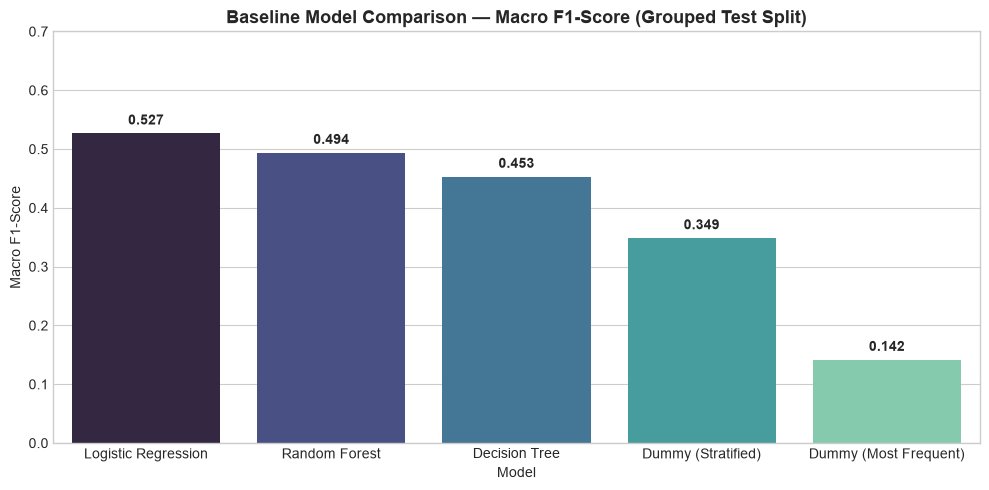

In [7]:
plt.figure(figsize=(10, 5))
sns.barplot(data=comp_df, x="Model", y="F1-Score (Macro)", palette="mako")
plt.title("Baseline Model Comparison — Macro F1-Score (Grouped Test Split)", fontsize=13, fontweight='bold')
plt.ylabel("Macro F1-Score")
plt.ylim(0, 0.7)
for i, v in enumerate(comp_df["F1-Score (Macro)"]):
    plt.text(i, v + 0.015, f"{v:.3f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Confusion Matrix for Best Model (Logistic Regression)

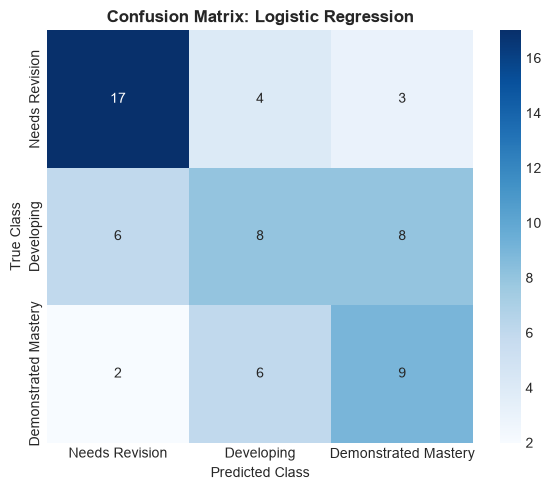

In [8]:
best_model_name = comp_df.iloc[0]["Model"]
best_pipe = trained_pipes[best_model_name]
best_cm = np.array(results[best_model_name]["confusion_matrix"])

plt.figure(figsize=(6, 5))
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES)
plt.title(f"Confusion Matrix: {best_model_name}", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()


## 8. Feature Coefficients / Feature Importance Interpretation

Logistic Regression Feature Weights for Predicting 'Demonstrated Mastery':
                      Feature  Coefficient (Mastery)
   topic_topic_dvc_version_01               0.640015
             confidence_score               0.541355
           completed_revision               0.249016
       prior_global_avg_score               0.227727
        topic_topic_superv_01               0.225696
         prior_topic_attempts               0.190650
    revision_duration_seconds               0.132488
        prior_topic_avg_score               0.023606
      topic_topic_bias_var_02              -0.000456
  topic_topic_mlflow_track_02              -0.030453
topic_topic_tree_ensembles_04              -0.264236
        prior_global_attempts              -0.384306
  topic_topic_eval_metrics_03              -0.619870


C:\Users\dhanu\AppData\Local\Temp\ipykernel_14916\3905775548.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_coef, x="Coefficient (Mastery)", y="Feature", palette="viridis")


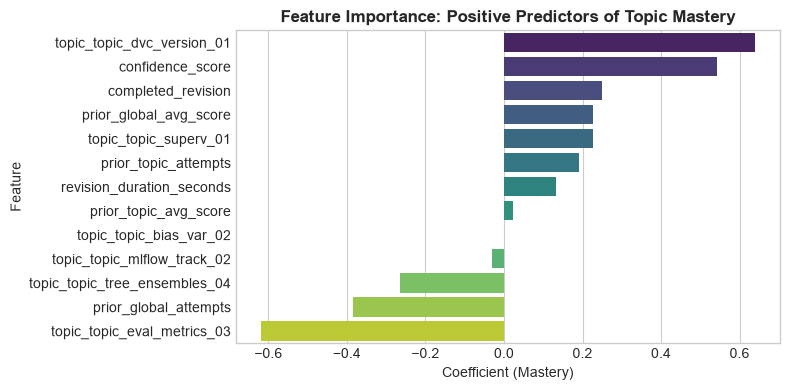

In [9]:
# Extract feature names from preprocessor
preproc_fitted = best_pipe.named_steps["preprocessor"]
cat_encoder = preproc_fitted.named_transformers_["cat"]
encoded_topic_names = [f"topic_{t}" for t in cat_encoder.categories_[0]]
all_feature_names = num_features + encoded_topic_names

if hasattr(best_pipe.named_steps["classifier"], "coef_"):
    coefs = best_pipe.named_steps["classifier"].coef_
    # For class 2: Demonstrated Mastery
    df_coef = pd.DataFrame({
        "Feature": all_feature_names,
        "Coefficient (Mastery)": coefs[2]
    }).sort_values(by="Coefficient (Mastery)", ascending=False)
    print("Logistic Regression Feature Weights for Predicting 'Demonstrated Mastery':")
    print(df_coef.to_string(index=False))

    plt.figure(figsize=(8, 4))
    sns.barplot(data=df_coef, x="Coefficient (Mastery)", y="Feature", palette="viridis")
    plt.title("Feature Importance: Positive Predictors of Topic Mastery", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


## 9. Model Inference Service & Fallback Contract Demonstration

In [10]:
predictor = MasteryPredictor()

print("1. Predicting using trained model artifact:")
pred_res = predictor.predict_readiness(
    student_id="std_live_01",
    topic_id="topic_superv_01",
    confidence_score=78.0,
    completed_revision=True,
    prior_topic_attempts=1,
    prior_topic_avg_score=75.0
)
print(pred_res)

print("\n2. Testing graceful fallback if model artifact is missing:")
fallback_predictor = MasteryPredictor(model_path="non_existent_path.joblib")
fallback_res = fallback_predictor.predict_readiness(
    student_id="std_live_02",
    topic_id="topic_superv_01",
    confidence_score=40.0,
    completed_revision=False,
    prior_topic_attempts=0
)
print(fallback_res)


1. Predicting using trained model artifact:
{'student_id': 'std_live_01', 'topic_id': 'topic_superv_01', 'predicted_band': 'Demonstrated Mastery', 'class_probabilities': {'Needs Revision': 0.0649, 'Developing': 0.1087, 'Demonstrated Mastery': 0.8265}, 'model_source': 'trained_baseline_model', 'is_fallback': False, 'recommended_action': 'High readiness detected. Take the quiz directly to validate your mastery.'}

2. Testing graceful fallback if model artifact is missing:
{'student_id': 'std_live_02', 'topic_id': 'topic_superv_01', 'predicted_band': 'Needs Revision', 'class_probabilities': {'Needs Revision': 0.7, 'Developing': 0.2, 'Demonstrated Mastery': 0.2}, 'model_source': 'calibrated_rule_fallback', 'is_fallback': True, 'recommended_action': 'Complete the concept summary and interactive flashcards before taking the quiz.'}


## 10. Limitations & Scientific Caveats

1. **Synthetic Cold-Start Benchmark**: All evaluations in this notebook were conducted on the Phase 1 bootstrap synthetic dataset. These metrics demonstrate **pipeline reproducibility**, mathematical sanity, and zero data leakage. They do NOT demonstrate pedagogical generalization to real human learners.
2. **Model Recommendations**: While Logistic Regression outperformed the baseline heuristics, model predictions are used as supportive advisory hints in the web UI. Core grading and readiness criteria are strictly based on empirical quiz evidence.
3. **Transition to Phase 2**: Once real student interactions accumulate via website telemetry, this reproducible pipeline will be re-run and tracked through MLflow and DVC.
